# 第2章　確率・統計・ベイズ推論の基礎

同じ温度で繰り返す測定の例です。未知の平均強度を $\theta$ と書き、事前分布と測定値を与えた後の分布を描きます。後半では別々の温度の潜在強度を二変量正規分布で表し、一方を知ったとき残りの予測がどう変わるかを確かめます。

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import norm

from experiment import BLUE, DTYPE, GREEN, ORANGE, QUALITY, save_figure, setup

setup()
prior_mean, prior_sd = 70.0, 5.0  # MPa
noise_sd = 3.0  # 1回の測定誤差の標準偏差 [MPa]
readings = np.array([71.0, 73.0, 72.0, 74.0], dtype=np.float64)
prior_precision = 1 / prior_sd**2
measurement_precision = 1 / noise_sd**2

n = len(readings)
variance = 1 / (prior_precision + n * measurement_precision)
mean = variance * (prior_mean * prior_precision + readings.sum() * measurement_precision)
print(f"測定後の平均: {mean:.3f} MPa")
print(f"測定後の標準偏差: {np.sqrt(variance):.3f} MPa")

測定後の平均: 72.294 MPa
測定後の標準偏差: 1.437 MPa


## 2.1 何を観測し、何を推定するか
観測値は配列の4つの数です。未知の平均強度は一つです。$\theta$ の密度を描き、観測を増やしたときの中心と幅を読み取ります。

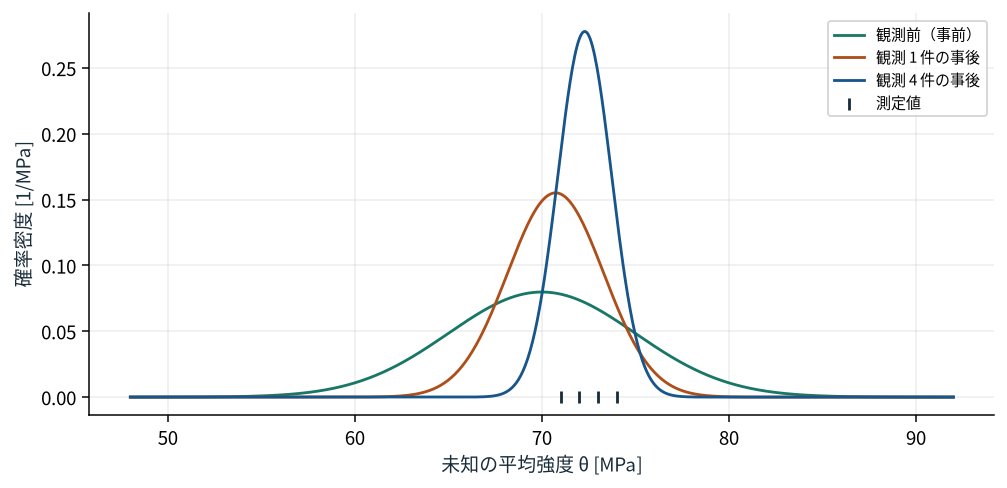

In [2]:
theta = np.linspace(48, 92, 701)
fig, ax = plt.subplots(figsize=(7.35, 3.5), layout="constrained")
updates = []
for count, color in zip((0, 1, 4), (GREEN, ORANGE, BLUE)):
    var_n = 1 / (prior_precision + count * measurement_precision)
    mu_n = var_n * (prior_mean * prior_precision + readings[:count].sum() * measurement_precision)
    sd_n = np.sqrt(var_n)
    updates.append({"observations": count, "mean_mpa": float(mu_n), "sd_mpa": float(sd_n)})
    ax.plot(theta, norm.pdf(theta, loc=mu_n, scale=sd_n), color=color,
            label="観測前（事前）" if count == 0 else f"観測 {count} 件の事後")
ax.scatter(readings, np.zeros_like(readings), marker="|", color="#192c3a", zorder=4, label="測定値")
ax.set(xlabel="未知の平均強度 θ [MPa]", ylabel="確率密度 [1/MPa]")
ax.legend(fontsize=8)
save_figure(fig, "ch02_updating_mean")

# 導出とは別に、事前密度と尤度の積をグリッドで正規化して照合する。
log_prior = norm.logpdf(theta, loc=prior_mean, scale=prior_sd)
log_likelihood = norm.logpdf(readings[None, :], loc=theta[:, None], scale=noise_sd).sum(axis=1)
unnormalized = np.exp(log_prior + log_likelihood - (log_prior + log_likelihood).max())
density = unnormalized / np.trapezoid(unnormalized, theta)
np.testing.assert_allclose(density, norm.pdf(theta, loc=mean, scale=np.sqrt(variance)), atol=1e-10)

## 2.5 二つの温度での強度を条件付きで予測する
$U$ と $V$ を別の温度における潜在強度とします。平均を $(72,75)$ MPa、標準偏差を $(4,5)$ MPa、相関を $0.7$ とし、$U=76$ MPa と分かったときの $V$ を考えます。周辺分布は $U$ の値で条件付ける前の分布です。

{
  "posterior_updates": [
    {
      "observations": 0,
      "mean_mpa": 70.0,
      "sd_mpa": 5.0
    },
    {
      "observations": 1,
      "mean_mpa": 70.73529411764704,
      "sd_mpa": 2.5724787771376323
    },
    {
      "observations": 4,
      "mean_mpa": 72.29357798165138,
      "sd_mpa": 1.4367394278317271
    }
  ],
  "measurement_noise_sd_mpa": 3.0,
  "new_measurement_sd_mpa": 3.326292257677644,
  "conditional_mean_mpa": 78.5,
  "conditional_sd_mpa": 3.570714214271425,
  "conditional_covariance_mpa2": 12.750000000000002
}


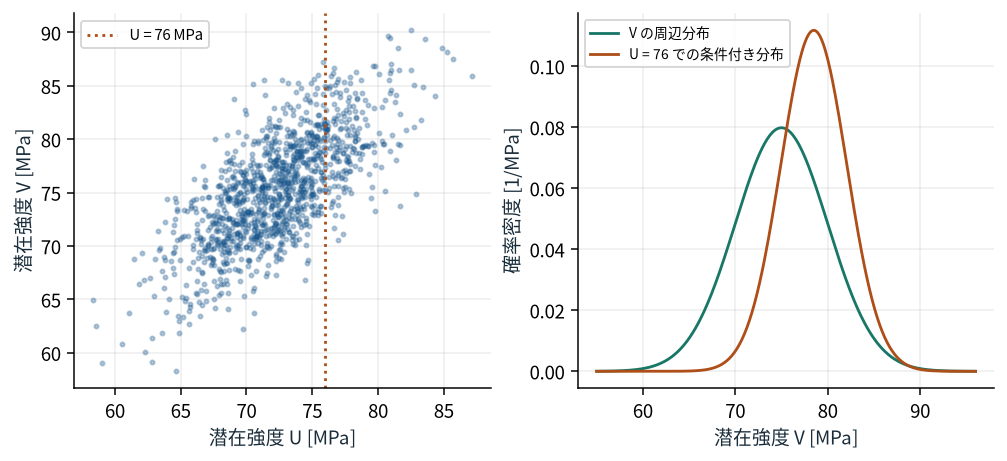

In [3]:
mu_u, mu_v = 72.0, 75.0
sd_u, sd_v = 4.0, 5.0
rho = 0.7
cross = rho * sd_u * sd_v
condition_u = 76.0
conditional_mean = mu_v + cross / sd_u**2 * (condition_u - mu_u)
conditional_sd = np.sqrt(sd_v**2 - cross**2 / sd_u**2)

location = torch.tensor([mu_u, mu_v], dtype=DTYPE)
covariance = torch.tensor([[sd_u**2, cross], [cross, sd_v**2]], dtype=DTYPE)
bivariate = torch.distributions.MultivariateNormal(location, covariance_matrix=covariance)
samples = bivariate.sample((1200,))
v = np.linspace(55, 96, 301)
inputs = torch.tensor(np.column_stack([np.full_like(v, condition_u), v]), dtype=DTYPE)
conditional_density = np.exp(bivariate.log_prob(inputs).numpy() -
                             norm.logpdf(condition_u, loc=mu_u, scale=sd_u))
np.testing.assert_allclose(conditional_density, norm.pdf(v, loc=conditional_mean, scale=conditional_sd),
                           rtol=1e-10, atol=1e-12)
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.35, 3.3), layout="constrained")
ax.scatter(samples[:, 0], samples[:, 1], color=BLUE, alpha=0.30, s=5)
ax.axvline(condition_u, color=ORANGE, linestyle=":", label="U = 76 MPa")
ax.set(xlabel="潜在強度 U [MPa]", ylabel="潜在強度 V [MPa]")
ax.legend(loc="upper left", fontsize=8)
bx.plot(v, norm.pdf(v, loc=mu_v, scale=sd_v), color=GREEN, label="V の周辺分布")
bx.plot(v, conditional_density, color=ORANGE, label="U = 76 での条件付き分布")
bx.set(xlabel="潜在強度 V [MPa]", ylabel="確率密度 [1/MPa]")
bx.legend(loc="upper left", fontsize=7.4)
save_figure(fig, "ch02_conditional_normal")
metrics = {
    "posterior_updates": updates, "measurement_noise_sd_mpa": noise_sd,
    "new_measurement_sd_mpa": float(np.sqrt(variance + noise_sd**2)),
    "conditional_mean_mpa": conditional_mean, "conditional_sd_mpa": conditional_sd.item(),
    "conditional_covariance_mpa2": float(conditional_sd**2),
}
(QUALITY / "ch02_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
print(json.dumps(metrics, indent=2))

## 章末演習
1. **確認。** 測定1件 $y_1=71$ のときの事後平均と標準偏差を、2.5節の式で求めましょう。
2. **操作。** 測定の標準偏差を3 MPaから6 MPaに変え、4件の事後平均と標準偏差を比較しましょう。
3. **発展。** 相関係数を $0$ または $-0.7$ に変えると、同じ $U=76$ という情報は $V$ にどう影響しますか。相関と因果の違いも述べましょう。